# SAMI: stellar mass and velocity dispersion

**Goal:** select E and E/S0 galaxies, fit the stellar-mass form of the Faber–Jackson relation and compare it with the equation in the lecture. Then check whether changing the aperture changes the fit.

Run all cells in order with **`notebooks/` as the working directory**. Keep `data/` and `results/` beside that folder. The ZIP contains those folders and the original CSVs. The notebook needs NumPy, pandas, Matplotlib and SciPy.

This follows **Option 2 of the 2026 PHYS3116 brief**, not the separately uploaded 2025 assessment.


## 1. Load the tables

The two input catalogues give stellar masses, `kin` gives the stellar velocity dispersions and `morph` gives galaxy types. The supplied columns are already read as numbers. These cells are for those CSVs; replacement files would need checking again.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

gama = pd.read_csv('../data/InputCatGAMADR3.csv')
clusters = pd.read_csv('../data/samiDR3InputCatClusters.csv')
kin = pd.read_csv('../data/samiDR3StelKin.csv')
morph = pd.read_csv('../data/samiDR3VisualMorphology.csv')

print('GAMA:', len(gama))
print('Clusters:', len(clusters))
print('Kinematic observations:', len(kin))
print('Morphology:', len(morph))


GAMA: 5536
Clusters: 1433
Kinematic observations: 3426
Morphology: 3068


## 2. Put the input catalogues together

I stack the two sets of galaxies and keep the columns needed below. `catid` identifies a galaxy. Repeated IDs could multiply rows in a merge, so both printed checks must be zero before continuing.


In [2]:
parent = pd.DataFrame({
    'catid': np.concatenate((gama['catid'], clusters['catid'])),
    'mstar': np.concatenate((gama['mstar'], clusters['mstar'])),
    'bad_class': np.concatenate((gama['bad_class'], clusters['bad_class']))
})
parent = parent.dropna(subset=['catid'])

parent_counts = parent['catid'].value_counts()
morph_counts = morph['catid'].value_counts()
print('Repeated input IDs:', len(parent_counts[parent_counts > 1]))
print('Repeated morphology IDs:', len(morph_counts[morph_counts > 1]))


Repeated input IDs: 0
Repeated morphology IDs: 0


## 3. Check the measurements and merge

`sigma_re` is the stellar velocity dispersion in the Sérsic effective-radius aperture, in km/s; `sigma_re_err` is its quoted uncertainty. Both must be present and positive. These are basic numerical checks, not a full survey-quality definition.

Some galaxies have repeated observations. For these files, the cuts leave one usable observation per galaxy. **The usable-ID repeat check must also give zero. If any repeat check is nonzero, stop and decide which observations to use.** `cubeidpub` stays with each row so the observation can be traced. Inner merges keep IDs found in both tables.


In [3]:
kin_present = kin.dropna(subset=['catid', 'sigma_re', 'sigma_re_err'])
kin_good = kin_present[(kin_present['sigma_re'] > 0) & (kin_present['sigma_re_err'] > 0)]

kin_counts = kin_good['catid'].value_counts()
print('Repeated usable IDs:', len(kin_counts[kin_counts > 1]))

kin_cols = ['catid', 'cubeidpub', 'sigma_re', 'sigma_re_err',
            'sigma_3kpc_round', 'sigma_3kpc_round_err']

matched_input = pd.merge(kin_good[kin_cols], parent, on='catid')
merged = pd.merge(matched_input, morph[['catid', 'type']], on='catid')


Repeated usable IDs: 0


## 4. Choose the sample

I require mass, morphology and flag information, then use E = 0 and E/S0 = 0.5. E/S0 is transitional. Writing both codes avoids including the no-agreement code −9 with `type < 1`.

I retain the earlier `bad_class == 0` working rule. The supplied schema does not define the individual flag codes, so their meaning still needs confirming. This is not a verified complete survey-quality selection.

For the aperture comparison I also require positive, nonmissing 3 kpc dispersions and errors. **Both fits below use this same final sample.** The count table shows each step; the saved sample keeps galaxy and observation IDs.


In [4]:
complete = merged.dropna(subset=['mstar', 'type', 'bad_class'])
good = complete[complete['bad_class'] == 0]
ellipticals = good[(good['type'] == 0) | (good['type'] == 0.5)]

paired = ellipticals.dropna(subset=['sigma_3kpc_round', 'sigma_3kpc_round_err'])
sample = paired[(paired['sigma_3kpc_round'] > 0) & (paired['sigma_3kpc_round_err'] > 0)]

counts = pd.DataFrame({
    'step': ['Original observations', 'Re measurements present', 'Positive Re measurements',
             'Input matches', 'Morphology matches', 'Mass, type and flag present',
             'Zero flag code', 'E and E/S0', '3 kpc measurements present', 'Positive 3 kpc measurements'],
    'rows': [len(kin), len(kin_present), len(kin_good), len(matched_input), len(merged),
             len(complete), len(good), len(ellipticals), len(paired), len(sample)]
})
print(counts)
print('Final morphology counts:')
print(sample['type'].value_counts())


                          step  rows
0        Original observations  3426
1      Re measurements present  2251
2     Positive Re measurements  2251
3                Input matches  2250
4           Morphology matches  2250
5  Mass, type and flag present  2250
6               Zero flag code  2237
7                   E and E/S0   446
8   3 kpc measurements present   446
9  Positive 3 kpc measurements   446
Final morphology counts:
type
0.0    230
0.5    216
Name: count, dtype: int64


## 5. Fit the relation and compare with the lecture

The catalogue's `mstar` is already $\log_{10}(M_\star/M_\odot)$. I only need to log the dispersion, using $\log_{10}x=\ln x/\ln 10$.

I fit

$$\log_{10}\!\left(\frac{\sigma_e}{\mathrm{km\,s^{-1}}}\right)
=a\log_{10}\!\left(\frac{M_\star}{M_\odot}\right)+b.$$

The supplied Week 3 Monday lecture, PDF page 30, gives the Oh et al. (2020) equation with $a=0.285$ and $b=-0.845$. Using the same fitting direction makes the comparison clearer. `stats.linregress` is the unweighted straight-line fit from Tutorial 4; it does not use the quoted measurement errors as weights.

This is the **stellar-mass form**, not a measurement of the classical luminosity exponent in $L\propto\sigma^4$. Stellar mass and luminosity differ through the mass-to-light ratio.


Galaxies: 446
Slope: 0.3331111896493938 +/- 0.010039109515522577
Intercept: -1.3600227480340585 +/- 0.10564991179058392
Lecture slope: 0.285


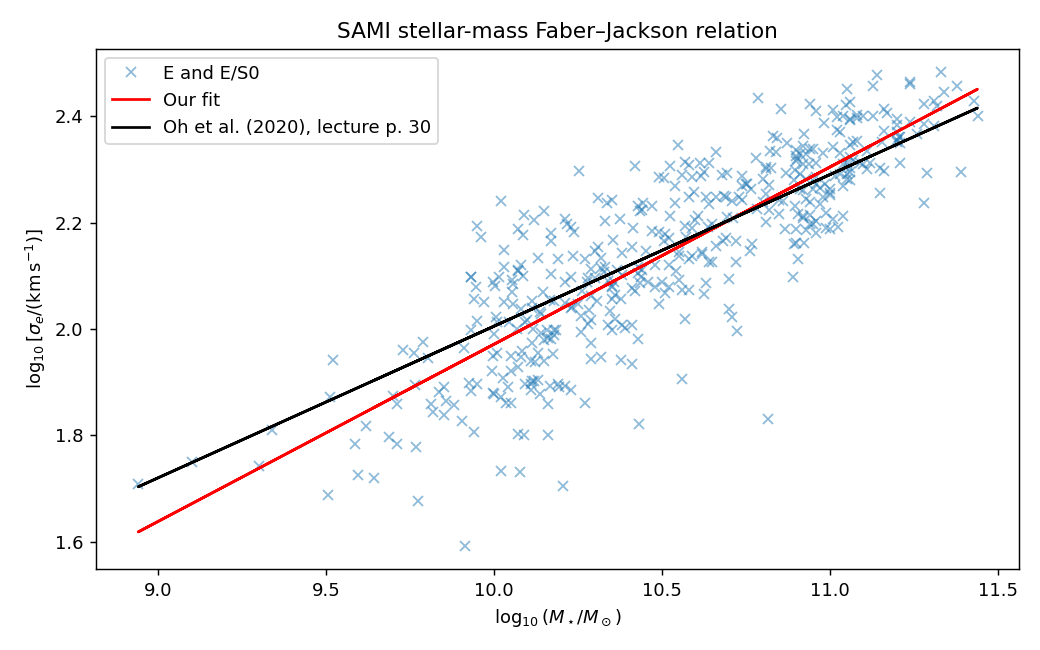

In [5]:
mass = np.array(sample['mstar'])
sigma = np.log(np.array(sample['sigma_re'])) / np.log(10)

fit = stats.linregress(mass, sigma)
line = fit.slope * mass + fit.intercept
lecture = 0.285 * mass - 0.845

print('Galaxies:', len(sample))
print('Slope:', fit.slope, '+/-', fit.stderr)
print('Intercept:', fit.intercept, '+/-', fit.intercept_stderr)
print('Lecture slope:', 0.285)

fig, ax = plt.subplots(figsize=(8, 5))
plt.plot(mass, sigma, 'x', alpha=0.5, label='E and E/S0')
plt.plot(mass, line, color='red', label='Our fit')
plt.plot(mass, lecture, color='black', label='Oh et al. (2020), lecture p. 30')
plt.xlabel(r'$\log_{10}(M_\star/M_\odot)$')
plt.ylabel(r'$\log_{10}[\sigma_e/(\mathrm{km\,s^{-1}})]$')
plt.title('SAMI stellar-mass Faber–Jackson relation')
plt.legend()
plt.tight_layout()
plt.show()


## 6. One extra check: change the aperture

The rubric asks for an idea beyond those suggested in the brief. Here I repeat the fit with the fixed 3 kpc aperture, using the same galaxies and observations. The apertures sample different parts of a galaxy, so spatial changes in stellar motions can affect the measured dispersion.


3 kpc slope: 0.3533969396817781 +/- 0.009841982760538753
3 kpc intercept: -1.5616809020800084 +/- 0.10357538274561204
Slope difference: 0.02028575003238431


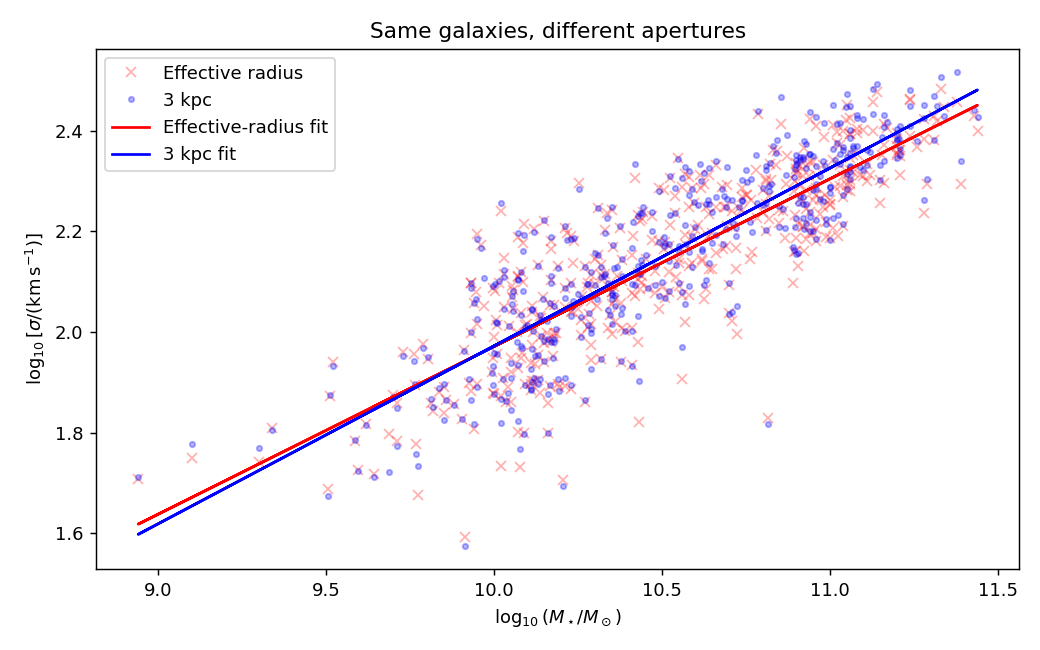

In [6]:
sigma_3kpc = np.log(np.array(sample['sigma_3kpc_round'])) / np.log(10)
fit_3kpc = stats.linregress(mass, sigma_3kpc)
line_3kpc = fit_3kpc.slope * mass + fit_3kpc.intercept

print('3 kpc slope:', fit_3kpc.slope, '+/-', fit_3kpc.stderr)
print('3 kpc intercept:', fit_3kpc.intercept, '+/-', fit_3kpc.intercept_stderr)
print('Slope difference:', fit_3kpc.slope - fit.slope)

fig, ax = plt.subplots(figsize=(8, 5))
plt.plot(mass, sigma, 'x', alpha=0.3, color='red', label='Effective radius')
plt.plot(mass, sigma_3kpc, '.', alpha=0.3, color='blue', label='3 kpc')
plt.plot(mass, line, color='red', label='Effective-radius fit')
plt.plot(mass, line_3kpc, color='blue', label='3 kpc fit')
plt.xlabel(r'$\log_{10}(M_\star/M_\odot)$')
plt.ylabel(r'$\log_{10}[\sigma/(\mathrm{km\,s^{-1}})]$')
plt.title('Same galaxies, different apertures')
plt.legend()
plt.tight_layout()
plt.show()


## 7. Save the sample and results

These three tables record the selection, the actual galaxies and the two fitted lines. Keep the supplied `results/` folder in place; `to_csv` does not create the folder.


In [7]:
fits = pd.DataFrame({
    'aperture': ['Effective radius', '3 kpc'],
    'N': [len(sample), len(sample)],
    'slope': [fit.slope, fit_3kpc.slope],
    'slope_error': [fit.stderr, fit_3kpc.stderr],
    'intercept': [fit.intercept, fit_3kpc.intercept],
    'intercept_error': [fit.intercept_stderr, fit_3kpc.intercept_stderr]
})

counts.to_csv('../results/selection_counts.csv', index=False)
sample.to_csv('../results/selected_galaxies.csv', index=False)
fits.to_csv('../results/fit_summary.csv', index=False)
print(fits)


           aperture    N     slope  slope_error  intercept  intercept_error
0  Effective radius  446  0.333111     0.010039  -1.360023         0.105650
1             3 kpc  446  0.353397     0.009842  -1.561681         0.103575


## 8. What the results say

The final sample contains **446 galaxies** (230 E and 216 E/S0). No E/E-S0 galaxies are lost when requiring both apertures in these files. The effective-radius slope is **0.333 ± 0.010**, compared with **0.285** in the lecture equation. The 3 kpc slope is **0.353 ± 0.010**. The change is **+0.020**. All slopes here describe log dispersion against log stellar mass; they are not mass-on-dispersion slopes or luminosity exponents.

More massive galaxies in this E/E-S0 sample generally have larger stellar velocity dispersions. This is consistent with the lecture's link between gravity and stellar motions. The virial argument relates gravitating mass, size and dispersion; stellar mass alone does not determine the dispersion.

The slope differs from the lecture equation. Sample selection, galaxy structure, measurement aperture and fitting assumptions could contribute. The slide's bulge-to-total category is not reproduced by this morphology selection, and the slide does not give all the reference fitting details or uncertainties. This comparison cannot isolate the reason for the difference.

The aperture check shows how sensitive the fitted relation is to the region measured. Its two fits share galaxies and have correlated uncertainties, so their separate slope errors do not establish the significance of their difference.

Elliptical galaxies are commonly described in terms of random stellar motions, while spiral disks also have ordered rotation. These dynamical differences matter when interpreting scaling relations and galaxy evolution. This notebook only fits E/E-S0 galaxies: it does not measure a spiral relation or prove a particular formation history.

**Limits and next step:** missing measurements make the sample incomplete; the flag meanings still need confirmation; the fit is unweighted and does not model errors in both axes or intrinsic scatter. Confirm the flag definitions and inspect unusual objects before making stronger claims. Update this discussion if the inputs change.

**Supplied sources:** 2026 assessment brief, pp. 3–5; SAMI schemas; Week 3 Monday lecture (`PHYS3116_2026T3_lecture_05_Mon3_vibe_annotated-1.pdf`), pp. 10–16 and 30; GalaxyML slides, pp. 2–7. Programming uses Tutorial 1 (variables, prints and counts), Tutorial 2 (CSV tables, merging and saving), Spotted Python Week 2 (`np.concatenate`, arrays), and Tutorial 4 / Spotted Python Weeks 3–4 (masks, logarithms, linear fitting and plotting).

**Outside the notebook:** the brief also requires genuine weekly team meetings and GitHub contributions for at least three weeks, a roughly 10-minute video with each member visible and speaking for at least two minutes, and an individual contribution/reflection statement with repository and profile links. The brief permits only simple AI editing and requires acknowledgement; this AI-assisted rewrite is not evidence of compliance with that rule.
